# Devices and calibration

Each twin is a device specification served by its own worker container. This notebook reads them through the API:
the native gates, the coupling map, and the calibration with the provenance of every number.

In [1]:
from qputwin_demo import *

connect()
devices = {backend: device(backend) for backend in BACKENDS}

pd.DataFrame({NAMES[b]: {
    "Vendor": d["vendor"],
    "Technology": d["technology"],
    "Qubit type": d["qubit_modality"],
    "Physical qubits": d["n_physical"],
    "Connectivity": d["connectivity"],
    "1Q native gates": ", ".join(d["native_gates"]["one_qubit"]),
    "2Q native gates": ", ".join(d["native_gates"]["two_qubit"]),
    "Entangler used for CX": d["entangler"],
} for b, d in devices.items()}).T

QPUTwin at http://localhost:8000: ready, 7 twins reachable


,Vendor,Technology,Qubit type,Physical qubits,Connectivity,1Q native gates,2Q native gates,Entangler used for CX
Helios,Quantinuum,trapped_ion,"137Ba+ hyperfine qubits, QCCD architecture",98,all_to_all,"u1q, rz","zzmax, rzz",zzmax
Forte,IonQ,trapped_ion,"171Yb+ hyperfine qubits, AOD-addressed linear ...",36,all_to_all,"gpi, gpi2, rz","ms, zz",ms
Ankaa-3,Rigetti,superconducting,fixed-frequency transmons with tunable couplers,84,nearest_neighbour,"rx, rz","cz, iswap",cz
Emerald,IQM,superconducting,transmons with tunable couplers (square lattice),54,nearest_neighbour,"prx, rz",cz,cz


## Coupling maps

A two-qubit gate is legal only between coupled qubits. The trapped-ion twins connect every pair, and the
superconducting twins couple nearest neighbours only. That difference drives most results in notebook 04.

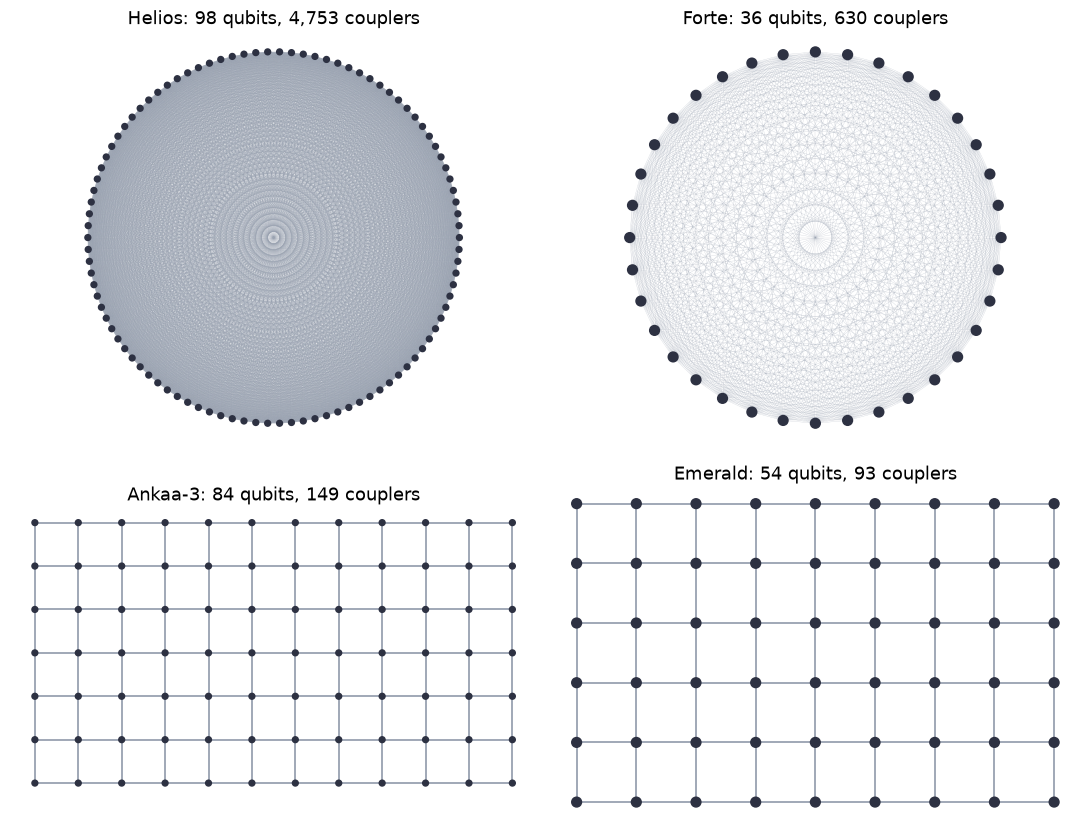

In [2]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, backend in zip(axes.flat, BACKENDS):
    plot_topology(backend, ax=ax)
fig.tight_layout()
plt.show()

Each map states where it comes from. The two lattices are synthetic: they match the published qubit count and
connectivity class, but they are not vendor calibration maps.

In [3]:
for backend, d in devices.items():
    print(f"{NAMES[backend]:8} {d['coupling_map']['provenance']}")

Helios   All-to-all via ion transport in a QCCD trap (modelled as K_98).
Forte    All-to-all through the shared motional bus (modelled as K_36).
Ankaa-3  Synthetic 7x12 nearest-neighbour square lattice matching the published qubit count and connectivity class of Rigetti Ankaa-3. Not a vendor calibration map.
Emerald  Synthetic 6x9 nearest-neighbour square lattice matching the published qubit count and connectivity class of IQM Emerald. Not a vendor calibration map.


## Calibration

These are the values the noise model and the scheduler use, as reported by each running worker.

In [4]:
rows = {}
for backend, d in devices.items():
    cal = d["calibration"]
    two_q = d["entangler"]
    one_q = next(g for g in d["native_gates"]["one_qubit"] if g != "rz")
    coherence = cal.get("coherence") or {}
    readout = cal.get("readout") or {}
    rows[NAMES[backend]] = {
        "1Q gate": one_q,
        "1Q fidelity": cal["gates"][one_q].get("fidelity"),
        "1Q duration (ns)": cal["gates"][one_q].get("duration_ns"),
        "2Q gate": two_q,
        "2Q fidelity": cal["gates"][two_q].get("fidelity"),
        "2Q duration (ns)": cal["gates"][two_q].get("duration_ns"),
        "Read-out error p01": round(readout.get("p01", float("nan")), 5),
        "T1 (µs)": coherence.get("t1_us"),
        "T2 (µs)": coherence.get("t2_us"),
    }
pd.DataFrame(rows).T

,1Q gate,1Q fidelity,1Q duration (ns),2Q gate,2Q fidelity,2Q duration (ns),Read-out error p01,T1 (µs),T2 (µs)
Helios,u1q,0.999975,10000.0,zzmax,0.99921,100000.0,0.00033,None,None
Forte,gpi,0.9998,135000.0,ms,0.996,600000.0,0.005,10000000.0,1000000.0
Ankaa-3,rx,0.999,40.0,cz,0.99,72.0,0.03,30.0,20.0
Emerald,prx,0.9993,40.0,cz,0.995,60.0,0.03,54.7,16.6


## Provenance: published or assumed

QPUTwin never hides a guess. Each calibration field carries a note saying whether it was published or assumed, and why.
Fidelities are mostly published, and durations and coherence are mostly assumed, so absolute times from these twins
are order-of-magnitude estimates.

In [5]:
def provenance_class(note):
    first = note.split(":")[0].split(" ")[0]
    return first if first in ("published", "assumed", "unknown") else "not modelled"

notes = []
for backend, d in devices.items():
    for field, note in d["calibration"]["provenance"].items():
        notes.append({"Twin": NAMES[backend], "Field": field, "Class": provenance_class(note), "Note": note})
notes = pd.DataFrame(notes)

notes.pivot_table(index="Twin", columns="Class", values="Field", aggfunc="count", fill_value=0)

Class,assumed,not modelled,published,unknown
Twin,,,,
Ankaa-3,9,0,2,1
Emerald,5,0,4,1
Forte,10,0,4,1
Helios,6,1,3,1


In [6]:
pd.set_option("display.max_colwidth", 110)
notes[notes.Twin == "Emerald"][["Field", "Class", "Note"]].set_index("Field")

,Class,Note
Field,,
gates.cz.fidelity,published,"published: 99.5% median two-qubit (CZ) fidelity (IQM Resonance / Amazon Braket launch, 2025)"
gates.prx.fidelity,published,"published: 99.93% median single-qubit fidelity (Amazon Braket launch coverage, 2025)"
coherence.t1_us,published,"published (third-party snapshot): median T1 = 54.7 us, arXiv:2608.30176 (Aug 2026)"
coherence.t2_us,published,"published (third-party snapshot): median T2 = 16.6 us, arXiv:2608.30176 (Aug 2026)"
gates.prx.duration_ns,assumed,assumed: placeholder
gates.cz.duration_ns,assumed,assumed: placeholder
readout.fidelity,assumed,"assumed: IQM Radiance typical readout (product family, not Emerald-specific)"
readout.duration_ns,assumed,assumed: placeholder
reset.duration_ns,assumed,assumed: placeholder


A noisy result lists exactly which parameters it relied on, grouped the same way. A worker started with
`QPUTWIN_REQUIRE_PUBLISHED_CALIBRATION=1` refuses any noisy run that needs an assumed value.

In [7]:
report = run("iqm_emerald", bell(), noise=True)["result"]["noise"]
{key: report["parameters_used"][key] for key in ("published", "assumed")}

{'published': ['coherence.t1_us',
  'coherence.t2_us',
  'gates.cz.fidelity',
  'gates.prx.fidelity'],
 'assumed': ['gates.cz.duration_ns',
  'gates.prx.duration_ns',
  'readout.fidelity']}